In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
conn = sqlite3.connect(db_path)
query = f"SELECT ts, ticker, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned WHERE ticker = '{ticker}' AND ts BETWEEN '{start_date}' AND '{end_date}' ORDER BY ts"
data = pd.read_sql(query, conn)
conn.close()

data["ts"] = pd.to_datetime(data["ts"])
data = data.set_index("ts")
data.head()

,ticker,open,high,low,close,adj_close,volume
ts,,,,,,,
2024-01-02,AAPL,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,AAPL,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,AAPL,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,AAPL,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,AAPL,182.09,185.60,181.50,185.56,184.86,59144470


In [4]:
print(f"{ticker} from {start_date} to {end_date}: {len(data)} trading days")
print("Actual first date:", data.index[0].date())
print("Actual last date:", data.index[-1].date())

display(data.head(), data.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual first date: 2024-01-02
Actual last date: 2024-10-18


,ticker,open,high,low,close,adj_close,volume
ts,,,,,,,
2024-01-02,AAPL,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,AAPL,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,AAPL,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,AAPL,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,AAPL,182.09,185.60,181.50,185.56,184.86,59144470


,ticker,open,high,low,close,adj_close,volume
ts,,,,,,,
2024-10-14,AAPL,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,AAPL,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,AAPL,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,AAPL,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,AAPL,236.18,236.18,234.01,235.00,235.00,45441281


In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility."""
    return returns.rolling(window).std() * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    peak = prices.cummax()
    return (prices - peak) / peak

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio. NaN if too few returns or zero volatility."""
    r = returns.dropna()
    if len(r) < 2 or r.std() == 0:
        return np.nan
    return (r.mean() * 252 - risk_free_rate) / (r.std() * np.sqrt(252))

In [6]:
prices = data["adj_close"]
returns = calculate_returns(prices)
vol = calculate_volatility(returns)
drawdown = calculate_max_drawdown(prices)
sharpe = calculate_sharpe_ratio(returns)

print("Sharpe ratio:", round(sharpe, 2))
print("Max drawdown:", round(drawdown.min(), 4))

Sharpe ratio: 1.19
Max drawdown: -0.1535


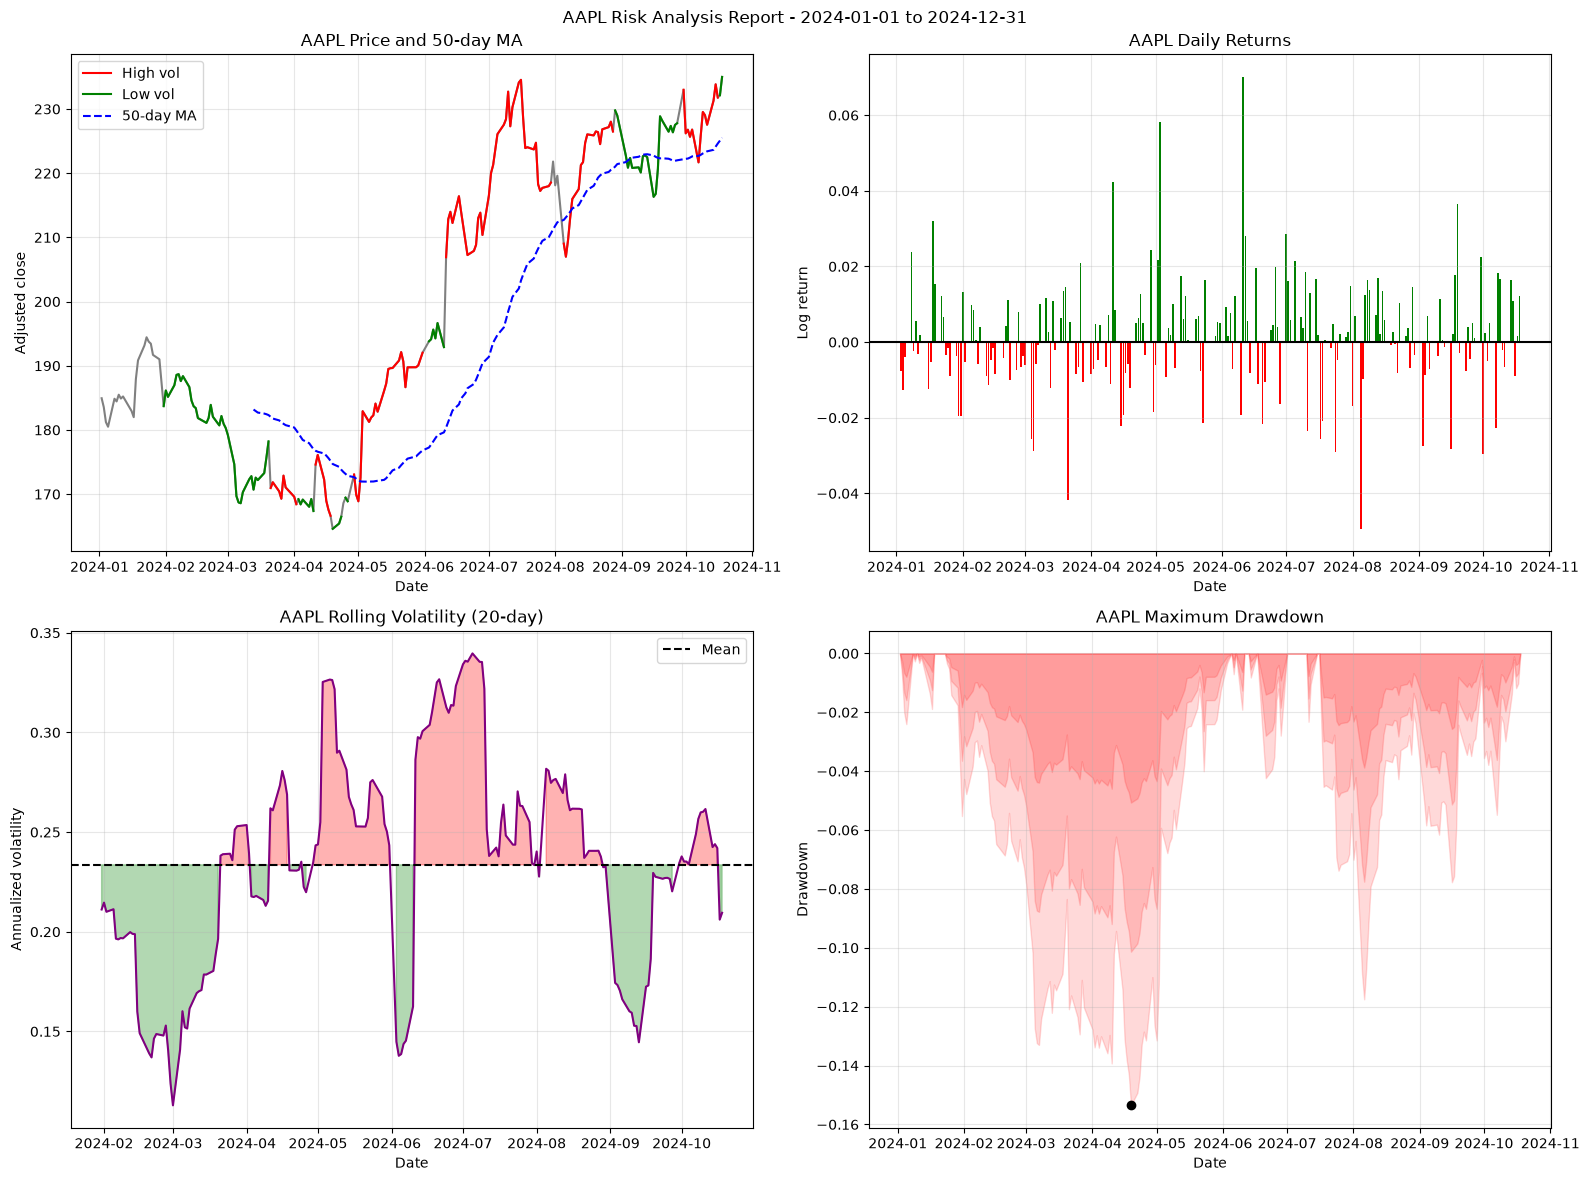

In [7]:
ma50 = prices.rolling(50).mean()
mean_vol = vol.mean()
r = returns.dropna()
high = vol > mean_vol
low = vol <= mean_vol

fig, ax = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}")

ax[0, 0].plot(prices, color="gray")
ax[0, 0].plot(prices.where(high), color="red", label="High vol")
ax[0, 0].plot(prices.where(low), color="green", label="Low vol")
ax[0, 0].plot(ma50, "b--", label="50-day MA")

ax[0, 1].bar(r.index, r, color=np.where(r >= 0, "green", "red"))
ax[0, 1].axhline(0, color="black")

ax[1, 0].plot(vol, color="purple")
ax[1, 0].axhline(mean_vol, color="black", linestyle="--", label="Mean")
ax[1, 0].fill_between(vol.index, vol, mean_vol, where=high, color="red", alpha=0.3)
ax[1, 0].fill_between(vol.index, vol, mean_vol, where=low, color="green", alpha=0.3)

for level in [1, 0.66, 0.33]:
    ax[1, 1].fill_between(drawdown.index, drawdown * level, 0, color="red", alpha=0.15)
ax[1, 1].scatter(drawdown.idxmin(), drawdown.min(), color="black")

titles = [f"{ticker} Price and 50-day MA", f"{ticker} Daily Returns",
          f"{ticker} Rolling Volatility (20-day)", f"{ticker} Maximum Drawdown"]
ylabels = ["Adjusted close", "Log return", "Annualized volatility", "Drawdown"]

axs = ax.flatten()
for i in range(4):
    axs[i].set_title(titles[i])
    axs[i].set_xlabel("Date")
    axs[i].set_ylabel(ylabels[i])
    axs[i].grid(alpha=0.3)

ax[0, 0].legend()
ax[1, 0].legend()
plt.tight_layout()
plt.show()

In [8]:
data["ratio"] = data["adj_close"] / data["close"]
data.loc[data["ratio"] > 2, ["close", "adj_close", "ratio"]]

,close,adj_close,ratio
ts,,,


In [9]:
r = returns.dropna()
n = len(r)

def pct(x):
    return "N/A" if pd.isna(x) else f"{x:+.2%}"

summary = pd.DataFrame({
    "Metric": ["Total Return", "Annualized Return", "Annualized Volatility",
               "Sharpe Ratio", "Maximum Drawdown", "Best Day", "Worst Day",
               "Positive Days", "Average Up Day", "Average Down Day"],
    "Value": [
        pct(prices.iloc[-1] / prices.iloc[0] - 1),
        pct(np.exp(r.sum() * 252 / n) - 1) if n > 0 else "N/A",
        f"{r.std() * np.sqrt(252):.2%}" if n > 1 else "N/A",
        f"{sharpe:.2f}" if pd.notna(sharpe) else "N/A",
        pct(drawdown.min()),
        pct(r.max()),
        pct(r.min()),
        f"{(r > 0).sum() / n:.1%}" if n > 0 else "N/A",
        pct(r[r > 0].mean()),
        pct(r[r < 0].mean()),
    ]
})

summary

,Metric,Value
0,Total Return,+27.07%
1,Annualized Return,+35.03%
2,Annualized Volatility,23.61%
3,Sharpe Ratio,1.19
4,Maximum Drawdown,-15.35%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,55.7%
8,Average Up Day,+1.08%
9,Average Down Day,-1.09%
